# Part A: Single-cell clustering of human blood immune cells (PBMC 3k)

About 2,700 peripheral blood mononuclear cells from one healthy donor, sequenced with 10x Genomics. Goal: go from a raw count matrix to labeled immune cell types, and keep a record of every choice.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 0
FIG = Path("../results/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path("../results/tables"); TAB.mkdir(parents=True, exist_ok=True)
PROC = Path("../data/processed"); PROC.mkdir(parents=True, exist_ok=True)

sc.settings.figdir = FIG
sc.settings.set_figure_params(dpi=100, dpi_save=150, facecolor="white")
sc.settings.verbosity = 2
sc.logging.print_header()  # package versions, for reproducibility

Package,Version
numpy,2.4.6
pandas,2.3.3
scanpy,1.11.5
matplotlib,3.11.2
Component,Info
Python,"3.11.16 (main, Aug 14 2026, 15:34:35) [MSC v.1944 64 bit (AMD64)]"
OS,Windows-10-10.0.26300-SP0
CPU,"8/8 logical CPU cores, Intel64 Family 6 Model 142 Stepping 12, GenuineIntel"
GPU,No GPU found
Updated,2026-11-15 20:12


## 1. Load data

Rows are cells (barcodes), columns are genes, values are UMI counts. The matrix is mostly zeros because each cell captures only a small fraction of its transcripts.

In [2]:
adata = sc.datasets.pbmc3k()   # downloads about 6 MB the first time
adata.var_names_make_unique()
n_cells_raw, n_genes_raw = adata.shape
print(adata)

try downloading from url
https://falexwolf.de/data/pbmc3k_raw.h5ad
... this may take a while but only happens once


  0%|          | 0.00/5.58M [00:00<?, ?B/s]

  0%|          | 8.00k/5.58M [00:00<02:04, 47.1kB/s]

  1%|          | 40.0k/5.58M [00:00<00:45, 129kB/s] 

  2%|▏         | 96.0k/5.58M [00:00<00:26, 216kB/s]

  4%|▎         | 208k/5.58M [00:00<00:14, 385kB/s] 

... (4 outputs left out)

 72%|███████▏  | 4.02M/5.58M [00:01<00:00, 5.65MB/s]

 99%|█████████▉| 5.52M/5.58M [00:01<00:00, 7.20MB/s]

100%|██████████| 5.58M/5.58M [00:01<00:00, 3.63MB/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


## 2. Quality control

- **Few genes detected:** empty droplets or broken cells.
- **Very many genes:** often doublets (two cells in one droplet).
- **High mitochondrial share:** the cell membrane leaked, so cytoplasmic RNA was lost and mitochondrial RNA dominates.

Look at the violin plots before accepting the thresholds below. They are the standard ones for this dataset, but you should be able to say why they fit.

filtered out 19024 genes that are detected in less than 3 cells


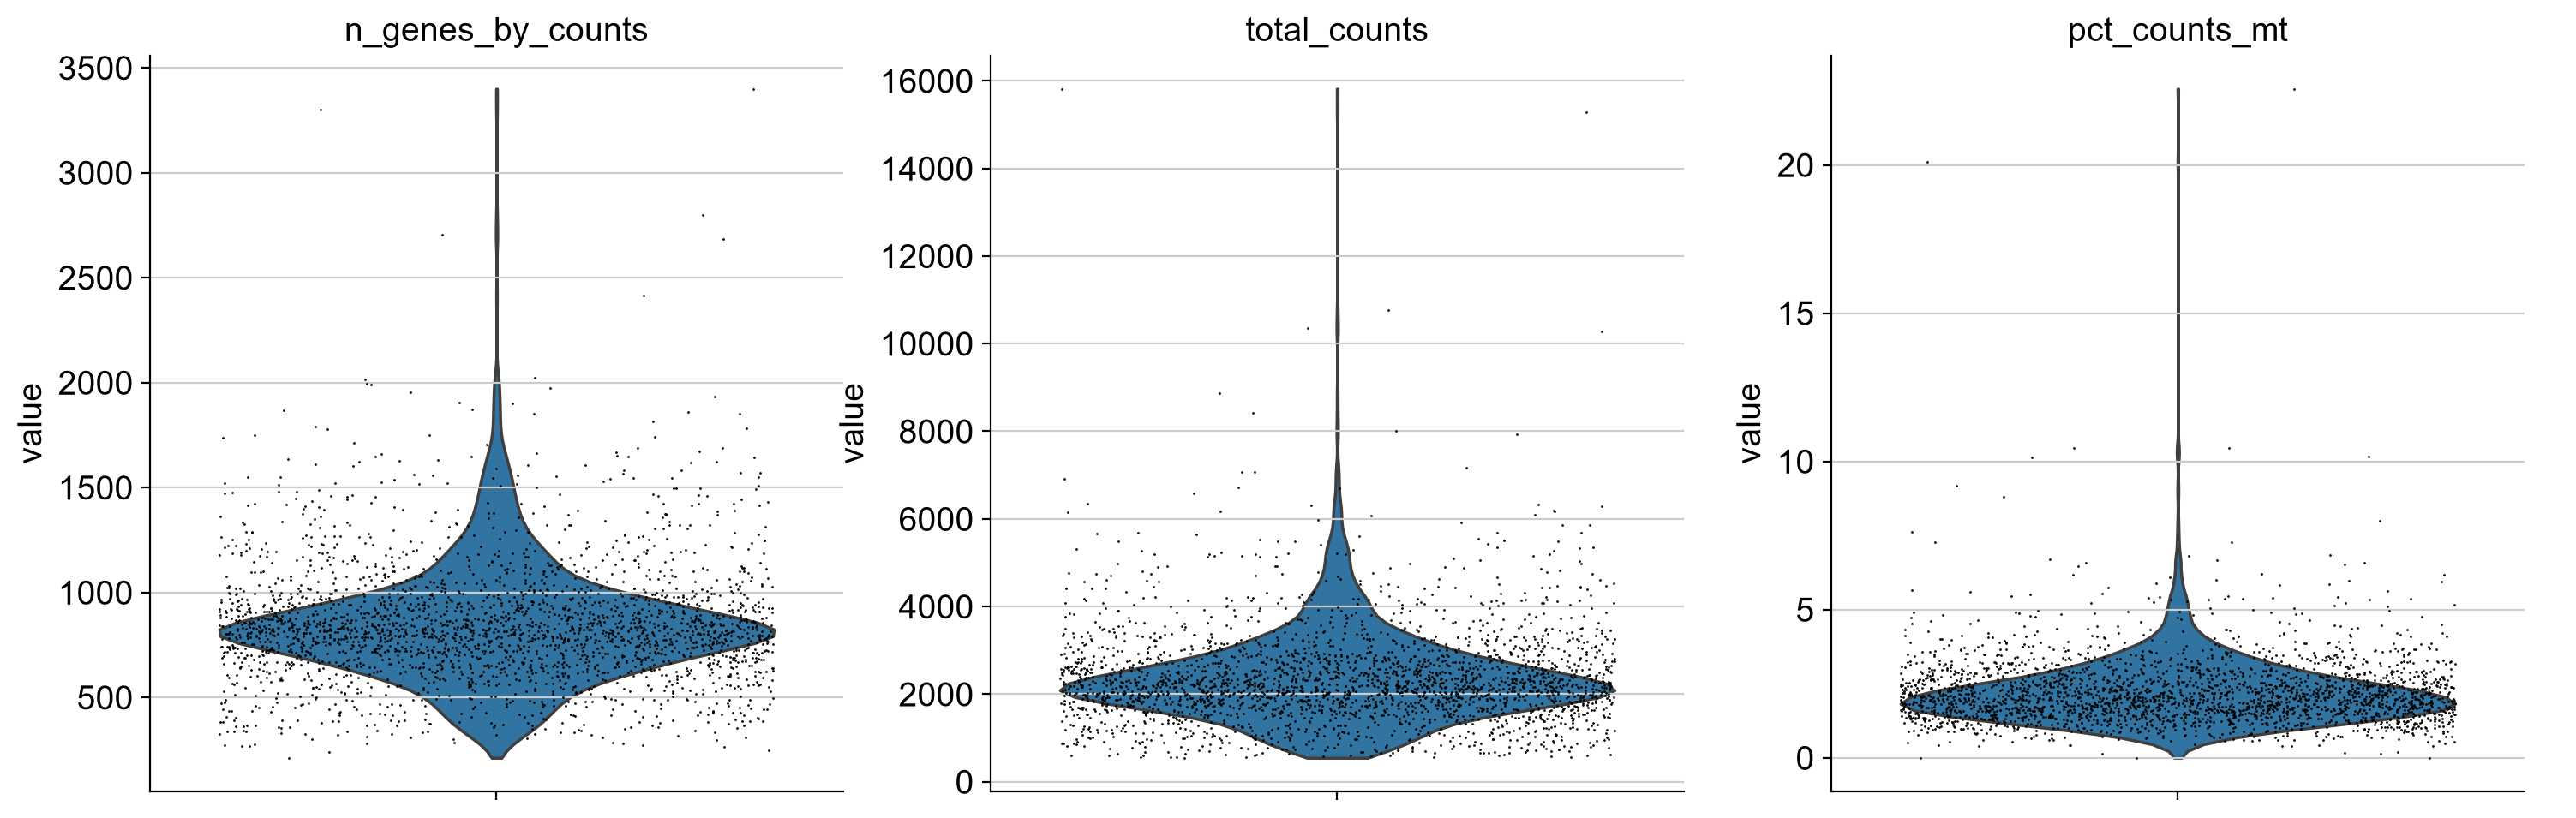

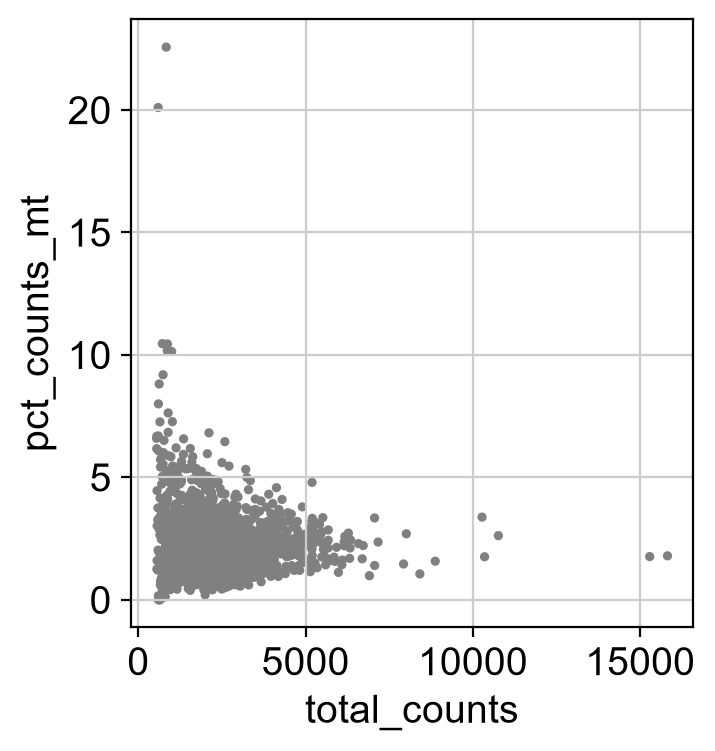

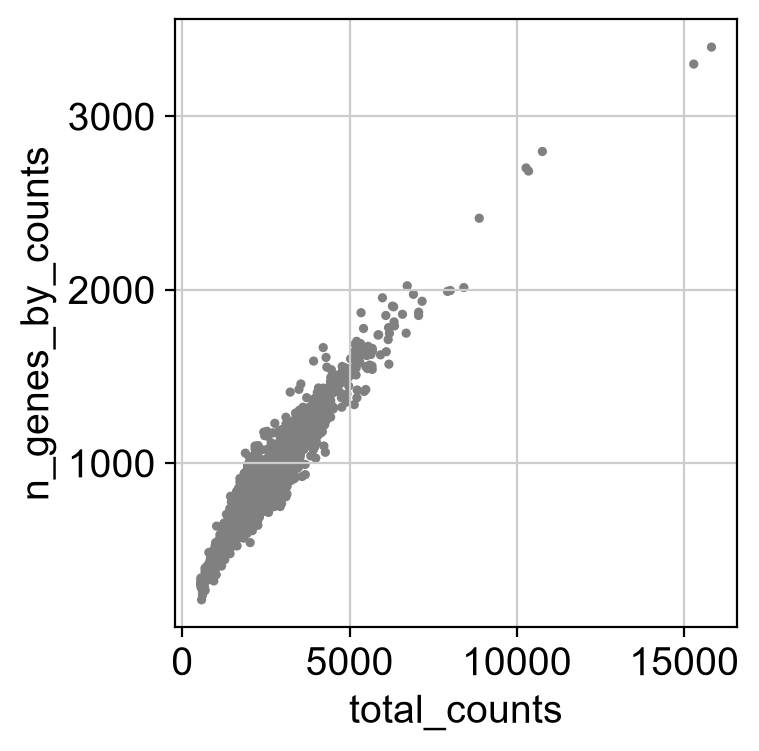

In [3]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True, save="_pbmc_qc.png")
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts")

In [4]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()
n_cells_qc, n_genes_qc = adata.shape
print(f"Cells: {n_cells_raw} raw -> {n_cells_qc} after QC; genes kept: {n_genes_qc}")

Cells: 2700 raw -> 2638 after QC; genes kept: 13714


## 3. Normalize, log-transform, select highly variable genes, scale

1. **Normalize total:** cells were sequenced to different depths, so scale each cell to 10,000 counts.
2. **log1p:** compresses the range so a few very high genes don't dominate.
3. **Highly variable genes (HVG):** most genes are flat across cells and only add noise. Keep genes that vary more than expected for their mean expression.
4. **Regress out and scale:** remove variation explained by depth and mitochondrial share, then give each gene unit variance so PCA treats them equally.

`adata.raw` keeps the full log-normalized matrix for marker plots later.

normalizing counts per cell


    finished (0:00:00)


extracting highly variable genes


    finished (0:00:00)


Highly variable genes: 1838


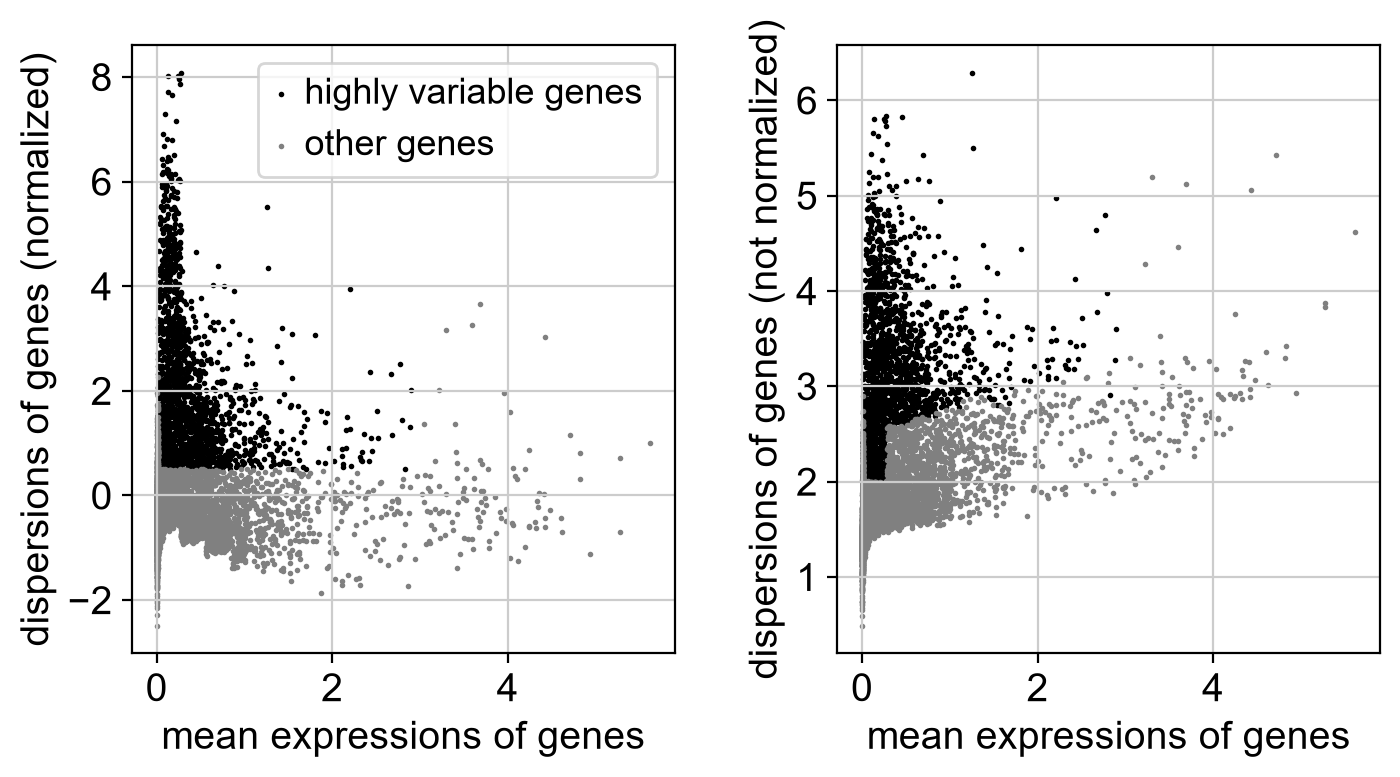

regressing out ['total_counts', 'pct_counts_mt']


    sparse input is densified and may lead to high memory use


    finished (0:00:00)


In [5]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
n_hvg = int(adata.var.highly_variable.sum())
print("Highly variable genes:", n_hvg)
sc.pl.highly_variable_genes(adata, save="_pbmc_hvg.png")

adata.raw = adata
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"])
sc.pp.scale(adata, max_value=10)

## 4. PCA

PCA compresses about 1,800 genes into a few axes that capture most of the structure. The elbow plot shows how much variance each PC explains. We use 40 PCs downstream. The rigor notebook checks whether results change with 10, 20 or 30.

computing PCA


    with n_comps=50


    finished (0:00:01)


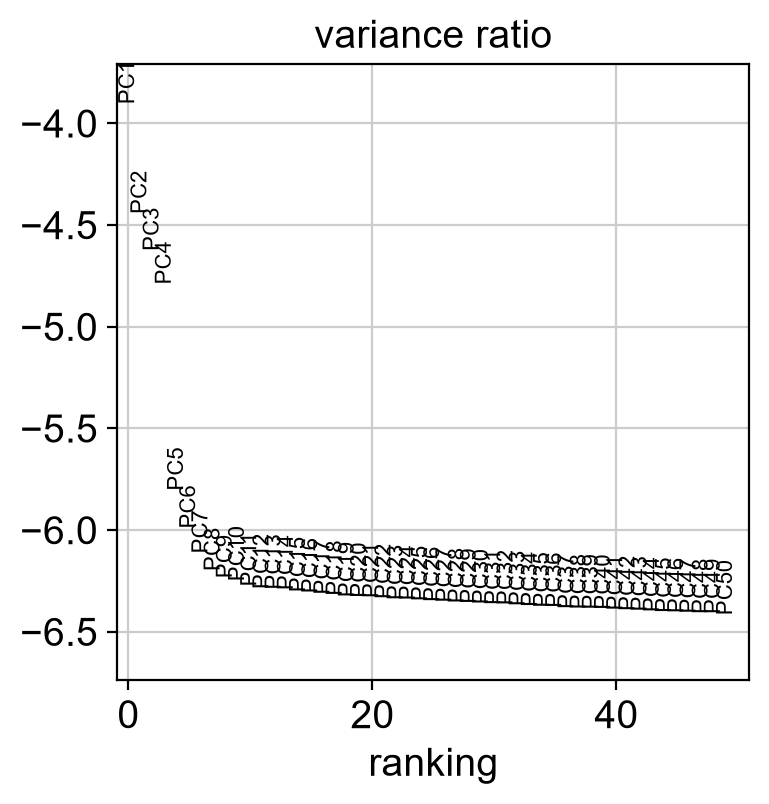

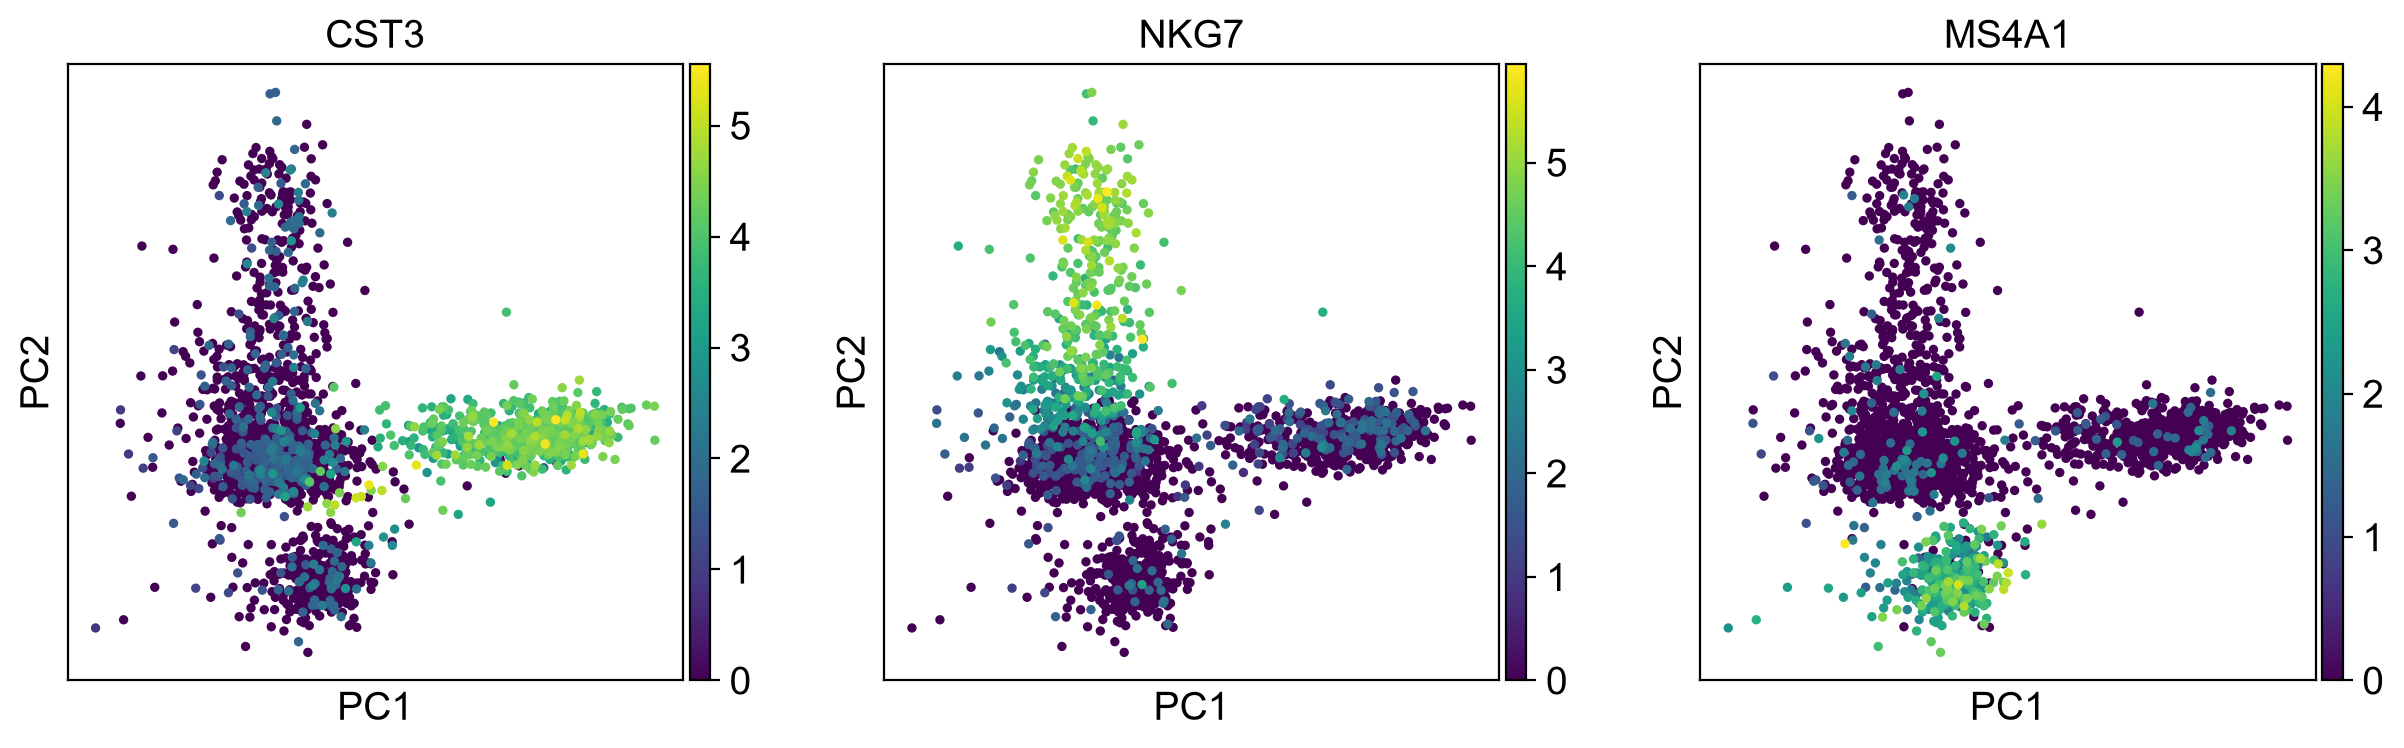

In [6]:
sc.tl.pca(adata, svd_solver="arpack", random_state=SEED)
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=50, save="_pbmc_elbow.png")
sc.pl.pca(adata, color=["CST3", "NKG7", "MS4A1"], save="_pbmc_pca_markers.png")

## 5. Neighbor graph, UMAP and t-SNE

The neighbor graph links each cell to its 10 most similar cells in PCA space. UMAP and t-SNE are 2D maps built for viewing. Distances between far-apart clusters on these maps don't mean much, so all analysis uses PCA space and the graph, never the 2D coordinates.

In [7]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
sc.tl.tsne(adata, n_pcs=40, random_state=SEED)

computing neighbors


    using 'X_pca' with n_pcs = 40


    finished (0:00:11)


computing UMAP


    finished (0:00:05)


computing tSNE


    using 'X_pca' with n_pcs = 40


    using sklearn.manifold.TSNE


    finished (0:00:17)


## 6. Leiden clustering

Leiden finds groups of cells that are more connected to each other than to the rest of the graph. **Resolution** controls granularity: higher values give more, smaller clusters. 0.9 is a common starting point for this dataset. The rigor notebook sweeps the resolution and seeds.

running Leiden clustering


    finished (0:00:00)


Leiden clusters: 8
leiden
0    1152
1     341
2     157
3     158
4     302
5     479
6      36
7      13
Name: count, dtype: int64


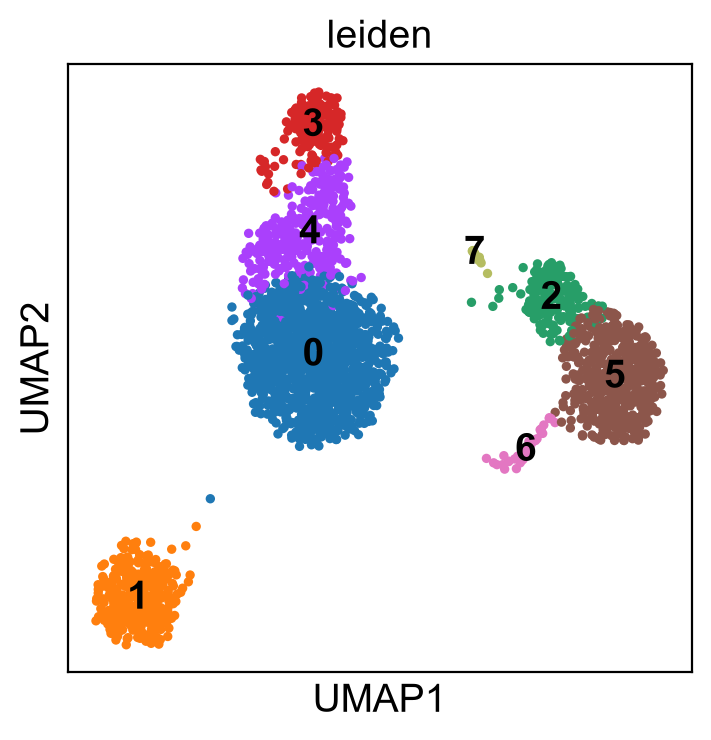

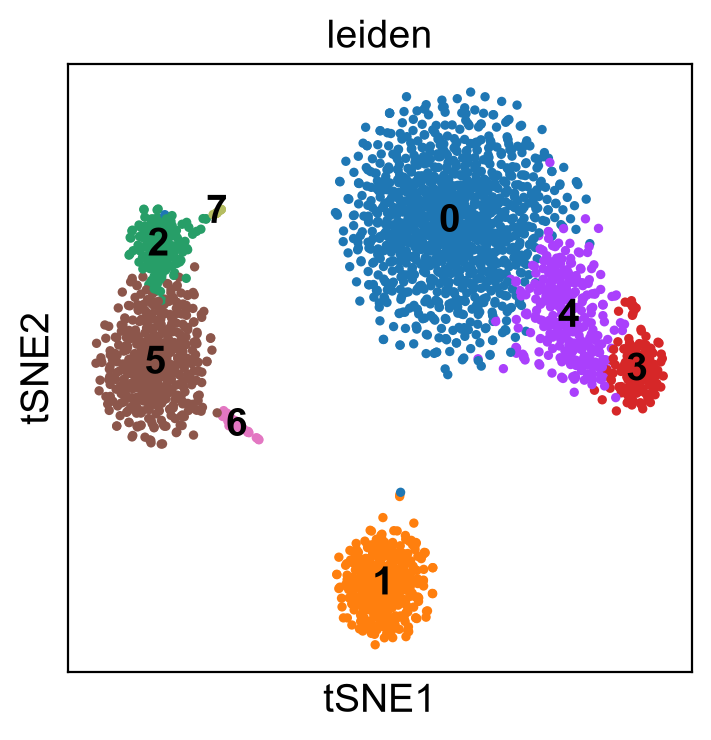

In [8]:
sc.tl.leiden(adata, resolution=0.9, key_added="leiden", random_state=SEED,
             flavor="igraph", n_iterations=2, directed=False)
n_clusters = adata.obs["leiden"].nunique()
print("Leiden clusters:", n_clusters)
print(adata.obs["leiden"].value_counts().sort_index())
sc.pl.umap(adata, color="leiden", legend_loc="on data", save="_pbmc_leiden.png")
sc.pl.tsne(adata, color="leiden", legend_loc="on data", save="_pbmc_tsne_leiden.png")

## 7. Marker genes (Wilcoxon rank-sum)

For each cluster, compare its cells against all other cells, gene by gene. Wilcoxon is rank-based, so it doesn't assume normally distributed expression, which single-cell data is not. P-values are Benjamini-Hochberg adjusted.

One caveat: the clusters were defined from the same data, so these p-values are optimistic. Use them to rank markers, not as proof that clusters differ.

ranking genes


    finished (0:00:01)


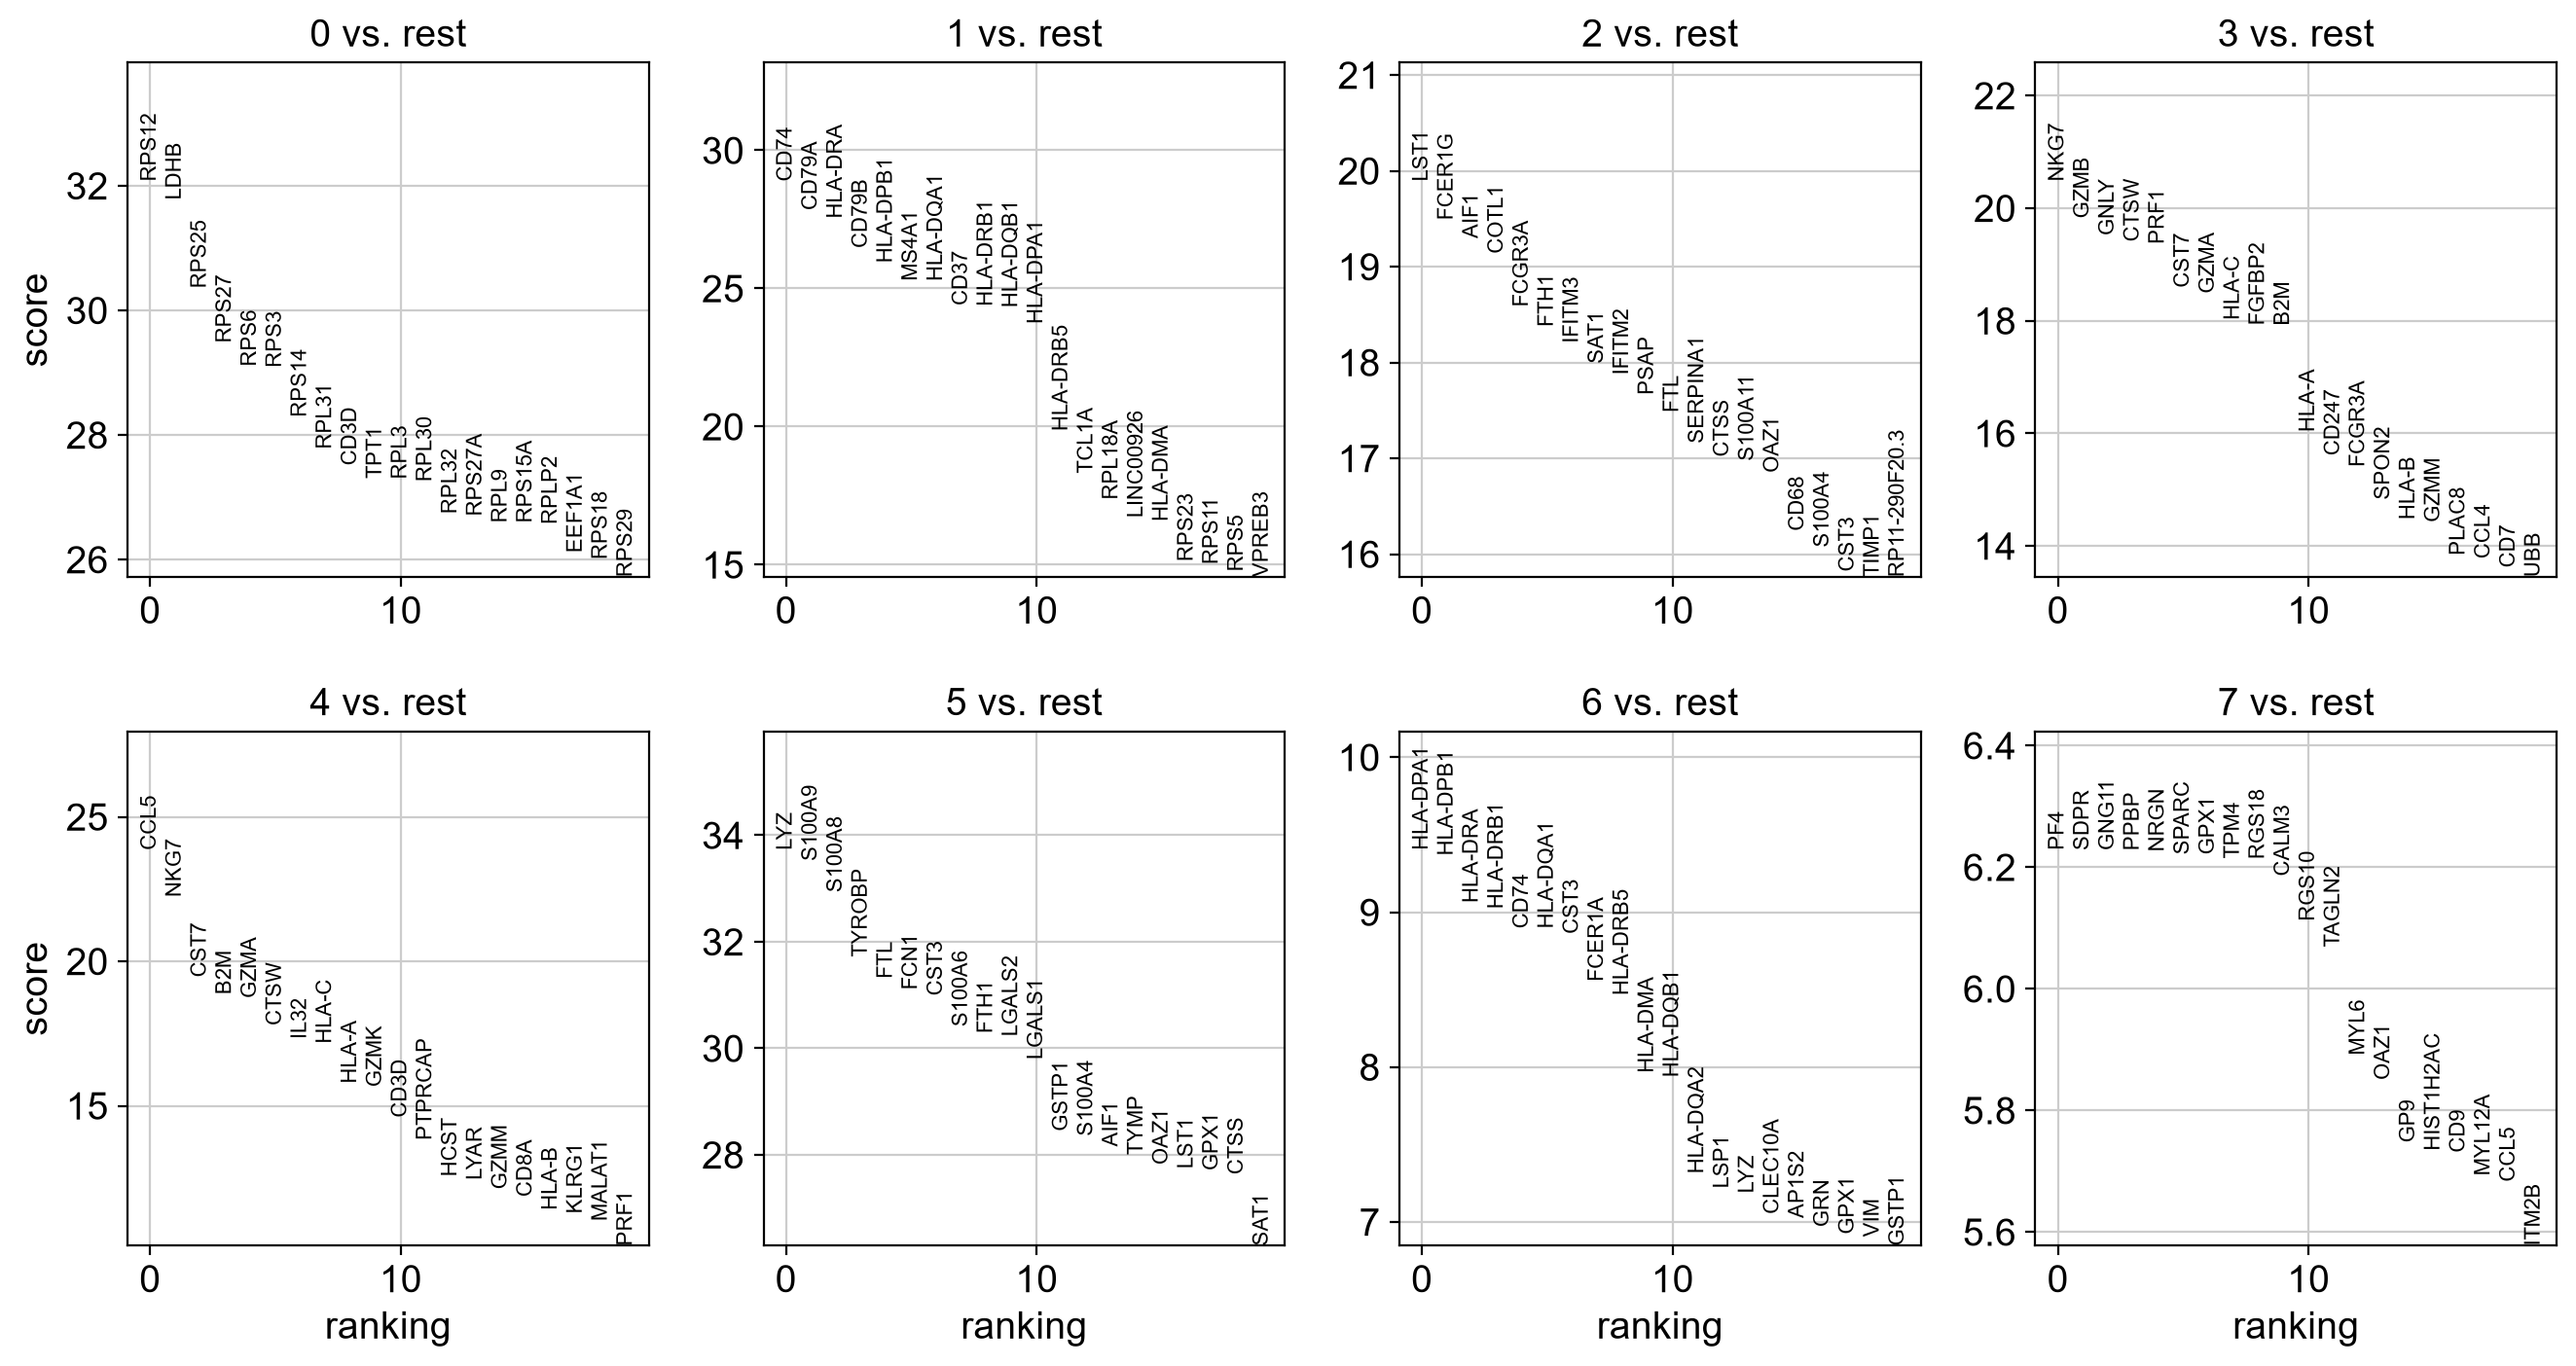

,0,1,2,3,4,5,6,7
0,RPS12,CD74,LST1,NKG7,CCL5,LYZ,HLA-DPA1,PF4
1,LDHB,CD79A,FCER1G,GZMB,NKG7,S100A9,HLA-DPB1,SDPR
2,RPS25,HLA-DRA,AIF1,GNLY,CST7,S100A8,HLA-DRA,GNG11
3,RPS27,CD79B,COTL1,CTSW,B2M,TYROBP,HLA-DRB1,PPBP
4,RPS6,HLA-DPB1,FCGR3A,PRF1,GZMA,FTL,CD74,NRGN
5,RPS3,MS4A1,FTH1,CST7,CTSW,FCN1,HLA-DQA1,SPARC
6,RPS14,HLA-DQA1,IFITM3,GZMA,IL32,CST3,CST3,GPX1
7,RPL31,CD37,SAT1,HLA-C,HLA-C,S100A6,FCER1A,TPM4
8,CD3D,HLA-DRB1,IFITM2,FGFBP2,HLA-A,FTH1,HLA-DRB5,RGS18
9,TPT1,HLA-DQB1,PSAP,B2M,GZMK,LGALS2,HLA-DMA,CALM3


In [9]:
sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon", use_raw=True)
sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False, save="_pbmc_markers.png")
top_markers = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(10)
top_markers.to_csv(TAB / "pbmc_top10_markers_per_cluster.csv", index=False)
top_markers

## 8. Assign cell types from known markers

| Cell type | Markers |
|---|---|
| CD4 T cells | CD3D, IL7R |
| CD8 T cells | CD3D, CD8A |
| B cells | MS4A1 |
| NK cells | NKG7, GNLY |
| CD14 monocytes | CD14, LYZ |
| FCGR3A (CD16) monocytes | FCGR3A, MS4A7 |
| Dendritic cells | FCER1A, CST3 |
| Platelets | PPBP |

Read the dotplot and the marker table above, then **fill in the mapping yourself**. Your cluster numbers may not match any tutorial. If a cluster is unclear, label it "Unclear" and say why in the interpretation. Don't force it.

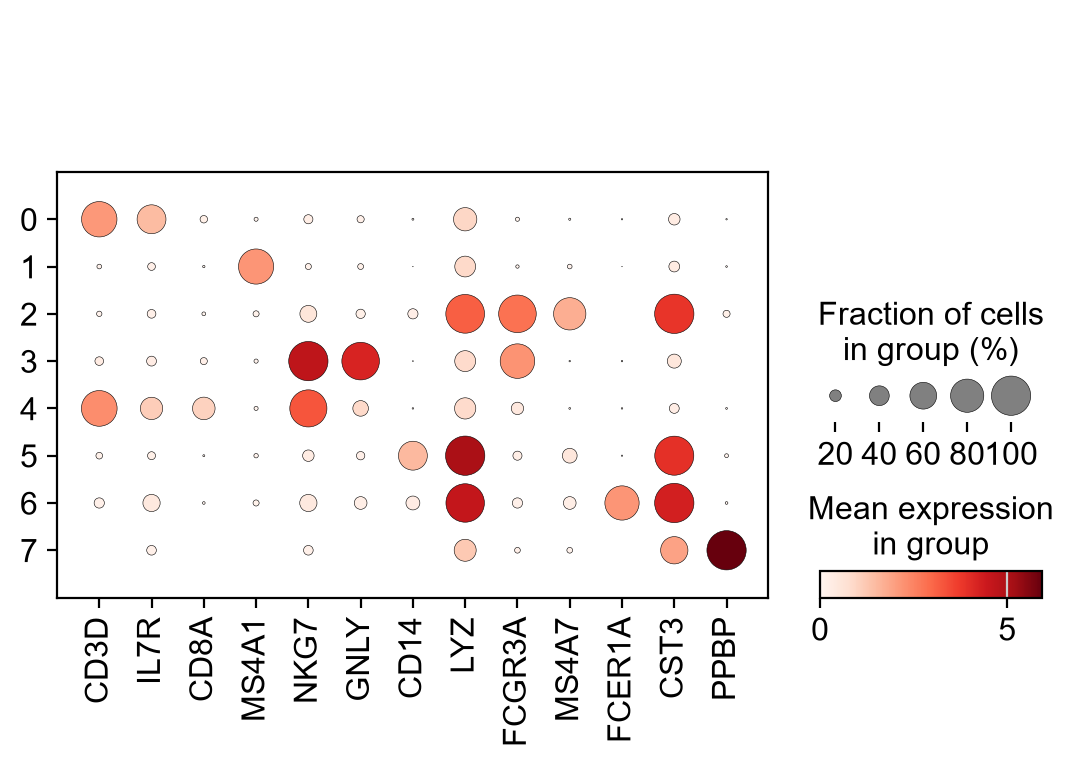

In [10]:
markers = ["CD3D", "IL7R", "CD8A", "MS4A1", "NKG7", "GNLY", "CD14", "LYZ",
           "FCGR3A", "MS4A7", "FCER1A", "CST3", "PPBP"]
missing_markers = [g for g in markers if g not in adata.raw.var_names]
if missing_markers:
    print("Not in data after filtering:", missing_markers)
markers = [g for g in markers if g in adata.raw.var_names]
sc.pl.dotplot(adata, markers, groupby="leiden", use_raw=True, save="_pbmc_marker_dotplot.png")

Cell types: 8
cell_type
CD4 T cells                1152
CD14 monocytes              479
B cells                     341
CD8 T cells                 302
NK cells                    158
FCGR3A (CD16) monocytes     157
Dendritic cells              36
Platelets                    13
Name: count, dtype: int64


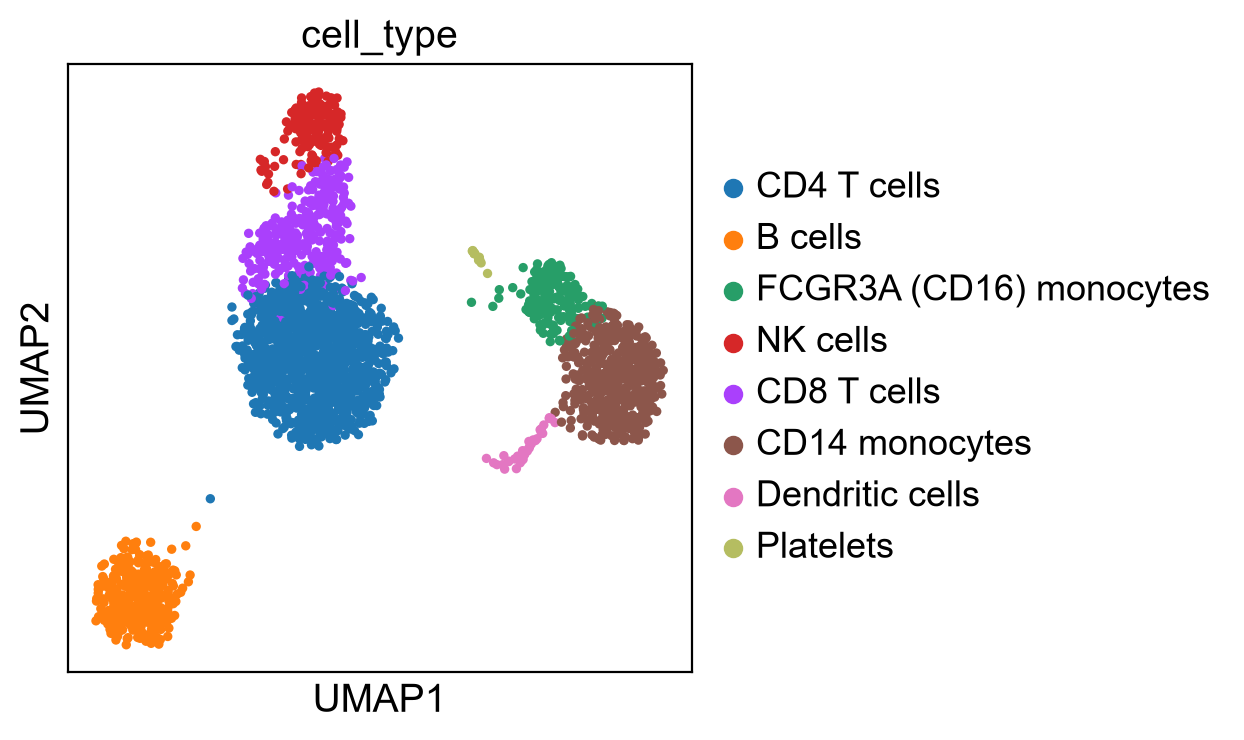

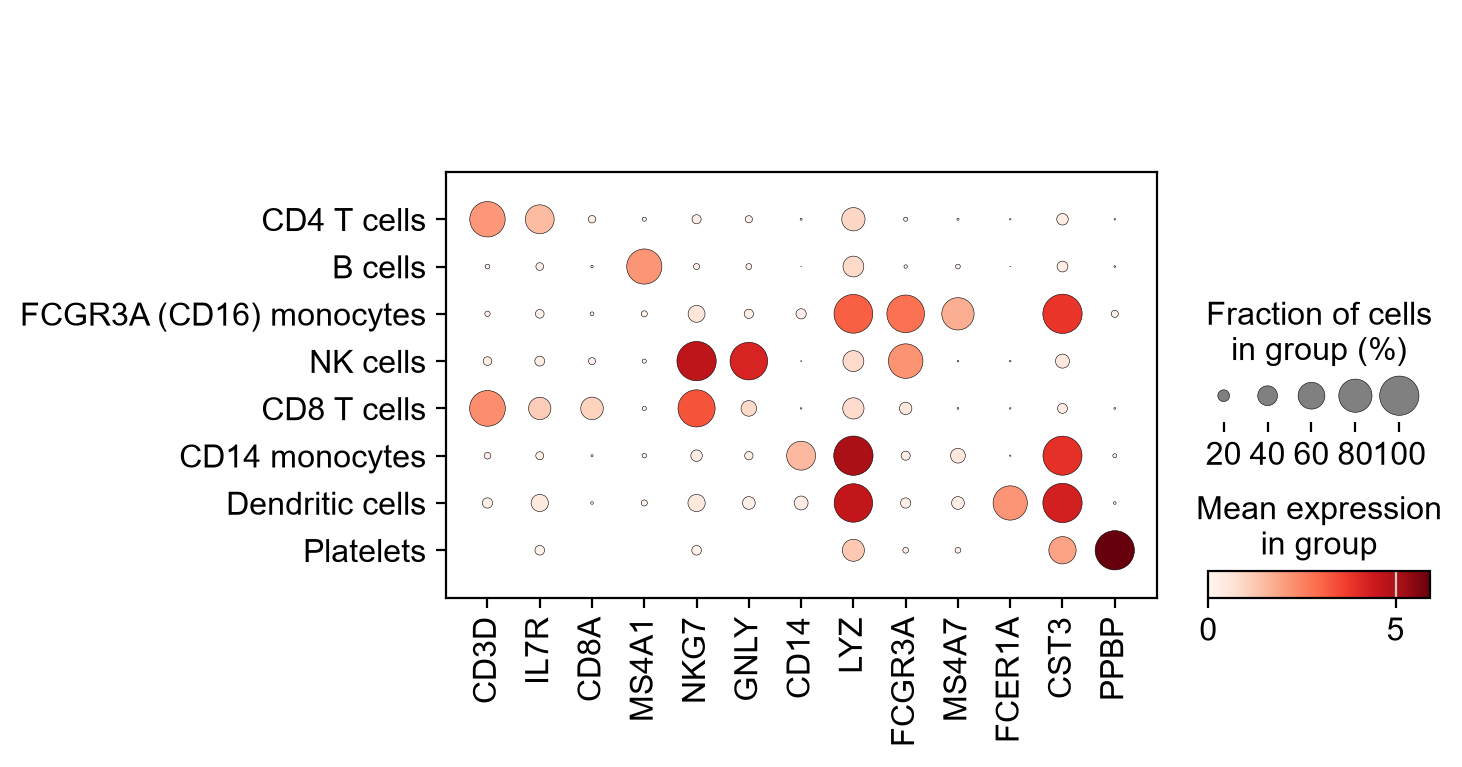

In [11]:
# Assigned from the marker dotplot and the top-10 marker table above.
# Every cluster number must appear exactly once.
cluster_to_type = {
    "0": "CD4 T cells",              # CD3D+, IL7R+, CD8A-; top markers LDHB, ribosomal genes
    "1": "B cells",                  # MS4A1, CD79A, CD79B, HLA class II
    "2": "FCGR3A (CD16) monocytes",  # FCGR3A, MS4A7, LST1, AIF1; CD14 low
    "3": "NK cells",                 # NKG7, GNLY, GZMB, PRF1; CD3D-
    "4": "CD8 T cells",              # CD3D+, CD8A+, CCL5, NKG7, GZMK
    "5": "CD14 monocytes",           # CD14, LYZ, S100A8, S100A9
    "6": "Dendritic cells",          # FCER1A, CST3, HLA class II
    "7": "Platelets",                # PPBP, PF4
}

missing = set(adata.obs["leiden"].cat.categories) - set(cluster_to_type)
assert not missing, f"Clusters without a label: {sorted(missing, key=int)}"

adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_type).astype("category")
n_cell_types = adata.obs["cell_type"].nunique()
print("Cell types:", n_cell_types)
print(adata.obs["cell_type"].value_counts())
sc.pl.umap(adata, color="cell_type", save="_pbmc_cell_types.png")
sc.pl.dotplot(adata, markers, groupby="cell_type", use_raw=True, save="_pbmc_celltype_dotplot.png")

## 9. Save and summarize

In [12]:
adata.write(PROC / "pbmc3k_processed.h5ad")
summary = {
    "cells_raw": n_cells_raw, "cells_after_qc": n_cells_qc, "genes_after_qc": n_genes_qc,
    "highly_variable_genes": n_hvg, "leiden_clusters_res0.9": n_clusters, "cell_types": n_cell_types,
}
pd.Series(summary).to_csv(TAB / "pbmc_summary.csv", header=["value"])
summary

{'cells_raw': 2700,
 'cells_after_qc': 2638,
 'genes_after_qc': 13714,
 'highly_variable_genes': 1838,
 'leiden_clusters_res0.9': 8,
 'cell_types': 8}

## Interpretation

QC kept 2,638 of 2,700 cells (removing high-mitochondrial and very high gene-count barcodes), and Leiden at resolution 0.9 gave 8 clusters. Each cluster matched exactly one canonical cell type. T cells dominate the sample: CD4 T cells are the largest group (1,152 cells, about 44%) and CD8 T cells add 302 (11%). Next come CD14 monocytes (479, 18%), B cells (341, 13%), NK cells (158, 6%) and FCGR3A monocytes (157, 6%), with small groups of dendritic cells (36, 1.4%) and platelets (13, 0.5%). These proportions are typical of healthy blood. The least certain label is CD8 T cells (cluster 4): its cells share NKG7, CCL5 and GZMK with NK cells, and only part of the cluster has detectable CD8A, which is expected given how sparse 10x data is. It is labeled CD8 because it is CD3D-positive and GNLY-low, unlike the NK cluster. The platelet cluster is tiny and probably reflects platelets stuck to other cells rather than true single cells. At this resolution CD4 T cells are one cluster, so naive and memory subsets are not separated. Because all cells come from one healthy donor, this analysis can say nothing about variation between people or about disease.